# 1. Exploratory Data Analysis (EDA)

This section explores the AI4I 2020 Predictive Maintenance dataset to understand its structure, assess data quality, and identify characteristics that may influence the machine learning workflow.

The analysis focuses on dataset structure, feature and target definition, target distribution, missing values, and data types.

In [1]:
import pandas as pd
import numpy as np

data=pd.read_csv("ai4i2020.csv")

x = data[["Type","Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]"]]
y = data["Machine failure"]

## 1.1. Dataset Overview

This subsection examines the dataset's dimensions, initial observations, and overall structure.

The objective is to understand the available variables and determine whether the dataset requires any initial data quality checks before further analysis.

In [2]:
x.shape,y.shape

((10000, 6), (10000,))

In [3]:
data.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
data.dtypes

UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

In [5]:
data.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


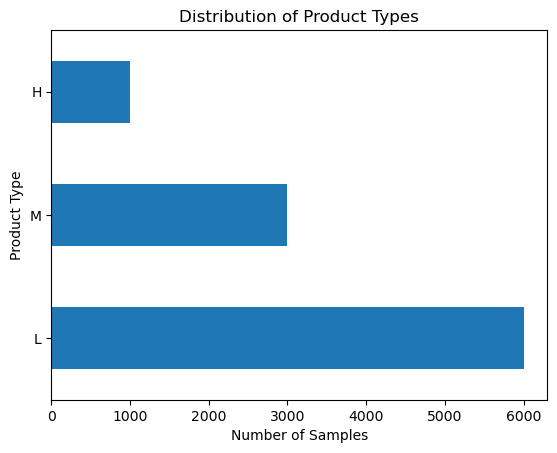

In [6]:
import matplotlib.pyplot as plt

data["Type"].value_counts().plot(kind="barh")

plt.xlabel("Number of Samples")
plt.ylabel("Product Type")
plt.title("Distribution of Product Types")
plt.show()

## 1.2. Data Types and Feature Types

The data types of the dataset columns are examined to distinguish numerical variables from categorical variables and identifiers.

This information will guide the preprocessing strategy, including categorical encoding where necessary and any scaling required by the selected machine learning algorithms.

In [7]:
x.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


In [8]:
y.dtypes

dtype('int64')

In [9]:
x.dtypes

Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
dtype: object

After examining the data types of the features, we found that the `Type` feature is stored as an object data type and contains categorical values. To prepare the dataset for machine learning, we will apply an appropriate encoding technique to convert these categorical values into a numerical representation.

## 1.3. Target Distribution and Class Imbalance

The distribution of the target variable is examined to determine the proportion of failure and non-failure observations.

Class imbalance is important because a model may achieve high accuracy by favoring the majority class while failing to identify a substantial proportion of actual failures.

Therefore, model performance will be evaluated using additional metrics, including precision, recall, F1-score, and average precision, rather than relying on accuracy alone.

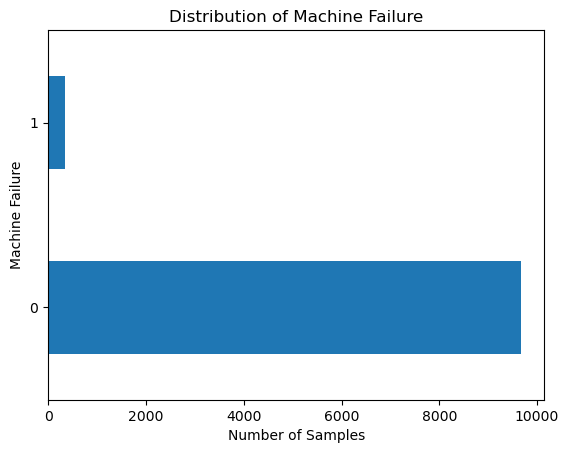

In [10]:
y.value_counts().plot(kind='barh')

plt.xlabel("Number of Samples")
plt.ylabel("Machine Failure")

plt.title("Distribution of Machine Failure")
plt.show()

In [11]:
y.value_counts(normalize=True)*100

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

## 1.4. Missing Values Analysis

Missing values are checked across all dataset columns to assess whether any imputation or missing-data handling is required.

The results of this analysis will determine whether a missing-value treatment step is necessary during preprocessing.

In [12]:
x.isna().sum()

Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
dtype: int64

In [13]:
y.isna().sum()

np.int64(0)

In [14]:
data.isna().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

**Finding:** No missing values were detected in the dataset. Therefore, missing-value imputation is not required based on this check.

##  1.5 Feature engineering

In this section, three new features are created to provide additional information about the machine's operating conditions and potential failure patterns.

The goal of feature engineering is to transform the existing variables into more informative representations that may help machine learning models identify relationships that are not easily captured by the original features.

The following features are introduced:

Temperature Difference [K]: Represents the difference between process temperature and air temperature. It provides information about the temperature gap during machine operation.

Power [W]: Represents the mechanical power generated by the machine, calculated using torque and rotational speed. This feature combines two existing variables into a single physical measurement.

Wear Torque Interaction: Represents the interaction between tool wear and torque. It may help capture how tool wear and mechanical load jointly relate to machine failure.

After creating these features, the engineered dataset (data_eng) is used to define the input features (x_eng) and target variable (y_eng).

The engineered feature set will be compared with the original feature set to investigate whether feature engineering improves model performance.

In [15]:
data_eng=data.copy()
# Temperature difference
data_eng["Temperature Difference [K]"] = (
    data["Process temperature [K]"]
    - data["Air temperature [K]"]
)

# Mechanical power in Watts
data_eng["Power [W]"] = (
    data["Torque [Nm]"]
    * data["Rotational speed [rpm]"]
    * (2 * np.pi / 60)
)

# Interaction between tool wear and torque
data_eng["Wear Torque Interaction"] = (
    data["Tool wear [min]"]
    * data["Torque [Nm]"]
)
x_eng=data_eng[["Type","Air temperature [K]","Temperature Difference [K]","Power [W]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]","Wear Torque Interaction"]]
y_eng=data_eng["Machine failure"]

## 1.6 Modeling Pipeline Strategy

A consistent preprocessing and modeling workflow will be used to ensure reliable and reproducible experiments.



In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

x_train_eng = x_eng.loc[x_train.index]
x_test_eng = x_eng.loc[x_test.index]

y_train_eng = y.loc[x_train.index]
y_test_eng = y.loc[x_test.index]


num_feature_org=["Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]"]
num_feature_eng=["Temperature Difference [K]","Power [W]","Wear Torque Interaction","Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]"]
cat_faeture=["Type"]

num_pipe=Pipeline([
    ("scale",StandardScaler())
])

cat_pipe=Pipeline([
    ("encoded",OrdinalEncoder(categories=[["L", "M", "H"]]))
])

preprocessor_org=ColumnTransformer([
    ("numeric",num_pipe,num_feature_org),
    ("categorical",cat_pipe,cat_faeture)
])
preprocessor_eng=ColumnTransformer([
    ("numeric",num_pipe,num_feature_eng),
    ("categorical",cat_pipe,cat_faeture)
])

## 1.7 Dummy Classifier Baseline
A Dummy Classifier was used as a baseline model to establish a minimum performance benchmark. It uses the most frequent class for all predictions and does not learn patterns from the input features. Since the dataset is imbalanced, this model may achieve high accuracy while failing to detect machine failures. Therefore, metrics such as Precision, Recall, and F1-score are also considered when evaluating the classification models.

In [17]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y = y_train.squeeze()

dummy = DummyClassifier(strategy="most_frequent")

# 5-fold Cross Validation
y_pred_dummy = cross_val_predict(
    dummy,
    x_train,
    y,
    cv=5,
    method="predict"
)

dummy_results = {
    "Model": "Dummy Classifier",
    "Accuracy": accuracy_score(y, y_pred_dummy),
    "Precision": precision_score(y, y_pred_dummy, zero_division=0),
    "Recall": recall_score(y, y_pred_dummy, zero_division=0),
    "F1-score": f1_score(y, y_pred_dummy, zero_division=0)
}

dummy_df = pd.DataFrame([dummy_results]).round(4)

dummy_df

,Model,Accuracy,Precision,Recall,F1-score
0,Dummy Classifier,0.9661,0.0,0.0,0.0


# 2. Model Training and Experimentation

This notebook focuses on training multiple machine learning classifiers to predict machine failures using the AI4I 2020 Predictive Maintenance dataset.

Each model is trained using a pipeline that combines the required preprocessing steps with the classification algorithm. This approach helps maintain a consistent workflow across experiments and reduces the risk of inconsistent preprocessing.

The following models are explored:

- Logistic Regression
- Random Forest
- Support Vector Machine (SVM)
- AdaBoost
- Gradient Boosting


## 2.1 Logistic Regression

In [18]:
from sklearn.linear_model import LogisticRegression

log_pipe_org=Pipeline([
("process",preprocessor_org),
("model",LogisticRegression(random_state=42))
])

log_pipe_eng=Pipeline([
("process",preprocessor_eng),
("model",LogisticRegression(random_state=42))
])

## 2.2 Random Forest

In [19]:
from sklearn.ensemble import RandomForestClassifier

forest_pipe_org=Pipeline([
    ("pre",preprocessor_org),
    ("model",RandomForestClassifier(random_state=42,n_estimators=200))
])

forest_pipe_eng=Pipeline([
    ("pre",preprocessor_eng),
    ("model",RandomForestClassifier(random_state=42,n_estimators=200))
])

## 2.3 Support Vector Machine (SVM)

In [20]:
from sklearn.svm import SVC

svm_pipe_org=Pipeline([
    ("pre",preprocessor_org),
    ("model",SVC(kernel="rbf",probability=True))
])

svm_pipe_eng=Pipeline([
    ("pre",preprocessor_eng),
    ("model",SVC(kernel="rbf",probability=True))
])

## 2.4 Gradient Boosting & AdaBoost

In [21]:
from sklearn.ensemble import GradientBoostingClassifier,AdaBoostClassifier

gb_pipe_org=Pipeline([
    ("pre",preprocessor_org),
    ("model",GradientBoostingClassifier())
])

gb_pipe_eng=Pipeline([
    ("pre",preprocessor_eng),
    ("model",GradientBoostingClassifier())
])


ada_pipe_org=Pipeline([
    ("pre",preprocessor_org),
    ("model",AdaBoostClassifier())
])

ada_pipe_eng=Pipeline([
    ("pre",preprocessor_eng),
    ("model",AdaBoostClassifier())
])


# 3.Model Comparison: Original vs. Engineered Features

In this section, five machine learning models are evaluated using both the original and engineered feature sets to investigate the impact of feature engineering on model performance.

A 5-fold Stratified Cross-Validation strategy is used to generate out-of-fold probability predictions for each model. Stratification ensures that the class distribution is approximately preserved across the folds.

The following evaluation metrics are calculated:

- **PR-AUC:** Evaluates the model's ability to identify failure cases across different classification thresholds. It is particularly useful for imbalanced datasets.
- **F1-score:** Measures the balance between precision and recall.
- **Precision:** Measures the proportion of predicted failures that are actual failures.
- **Recall:** Measures the proportion of actual failures correctly identified by the model.
- **Accuracy:** Measures the overall proportion of correct predictions.
- **Threshold:** The probability threshold that maximizes the F1-score.

The results are collected in a comparison table to assess whether the engineered features improve the performance of each model.

The PR-AUC score is used as the primary metric for comparing model performance, while the remaining metrics provide additional insight into classification behavior.

In [22]:
import numpy as np
import pandas as pd

from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import (
    precision_score,
    recall_score,
    accuracy_score,
    precision_recall_curve,
    average_precision_score,
    f1_score
)

results = []

y_true = y_train.to_numpy().ravel()

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = [
    ("Logistic Regression_eng", log_pipe_eng, x_train_eng),
    ("Logistic Regression_org", log_pipe_org, x_train),

    ("Random Forest_eng", forest_pipe_eng, x_train_eng),
    ("Random Forest_org", forest_pipe_org, x_train),

    ("Gradient Boosting_eng", gb_pipe_eng, x_train_eng),
    ("Gradient Boosting_org", gb_pipe_org, x_train),

    ("AdaBoost_eng", ada_pipe_eng, x_train_eng),
    ("AdaBoost_org", ada_pipe_org, x_train),

    ("SVM_eng", svm_pipe_eng, x_train_eng),
    ("SVM_org", svm_pipe_org, x_train)
]

for model_name, model, X in models:

    y_proba_cv = cross_val_predict(
        model,
        X,
        y_true,
        cv=cv,
        method="predict_proba"
    )[:, 1]

    pr_auc = average_precision_score(
        y_true, y_proba_cv
    )

    precisions, recalls, thresholds = precision_recall_curve(
        y_true, y_proba_cv
    )

    # Select threshold that maximizes F1
    f1_scores = (
        2 * precisions[:-1] * recalls[:-1]
        / (precisions[:-1] + recalls[:-1] + 1e-12)
    )

    best_idx = np.argmax(f1_scores)
    threshold = thresholds[best_idx]

    y_pred = (y_proba_cv >= threshold).astype(int)

    results.append({
        "Model": model_name,
        "Threshold": threshold,
        "PR-AUC": pr_auc,
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_true, y_pred)
    })

comparison = (
    pd.DataFrame(results)
    .reset_index(drop=True)
    .round(4)
)

comparison

,Model,Threshold,PR-AUC,F1,Precision,Recall,Accuracy
0,Logistic Regression_eng,0.2412,0.4958,0.5000,0.5221,0.4797,0.9675
1,Logistic Regression_org,0.1946,0.4602,0.4905,0.4610,0.5240,0.9631
2,Random Forest_eng,0.4900,0.8982,0.9000,0.9825,0.8303,0.9938
3,Random Forest_org,0.3400,0.7675,0.7625,0.7928,0.7343,0.9845
4,Gradient Boosting_eng,0.3557,0.9109,0.8932,0.9426,0.8487,0.9931
5,Gradient Boosting_org,0.3067,0.7788,0.7533,0.7817,0.7269,0.9839
6,AdaBoost_eng,0.4558,0.7588,0.8078,0.7801,0.8376,0.9865
7,AdaBoost_org,0.4390,0.5331,0.5232,0.4147,0.7085,0.9562
8,SVM_eng,0.1837,0.7201,0.6894,0.6713,0.7085,0.9784
9,SVM_org,0.1977,0.6604,0.6473,0.6380,0.6568,0.9758


## Preliminary Results and Model Selection

Based on the comparison table, the Random Forest, Gradient Boosting, and AdaBoost models showed more promising performance in the initial experiments compared to the other models.

Therefore, these three models will be selected for further investigation.

# 4.Threshold Analysis and Model Comparison with diagrams

The following plots illustrate how Precision and Recall change across different classification thresholds for the three selected models: Random Forest, Gradient Boosting, and AdaBoost.

As shown in the plots, changing the classification threshold affects the trade-off between Precision and Recall. The optimal threshold for each model is selected based on the highest F1-score.

The table below summarizes the Precision, Recall, and F1-score of the three models at their respective optimal thresholds, allowing us to compare their performance and identify the most suitable model.

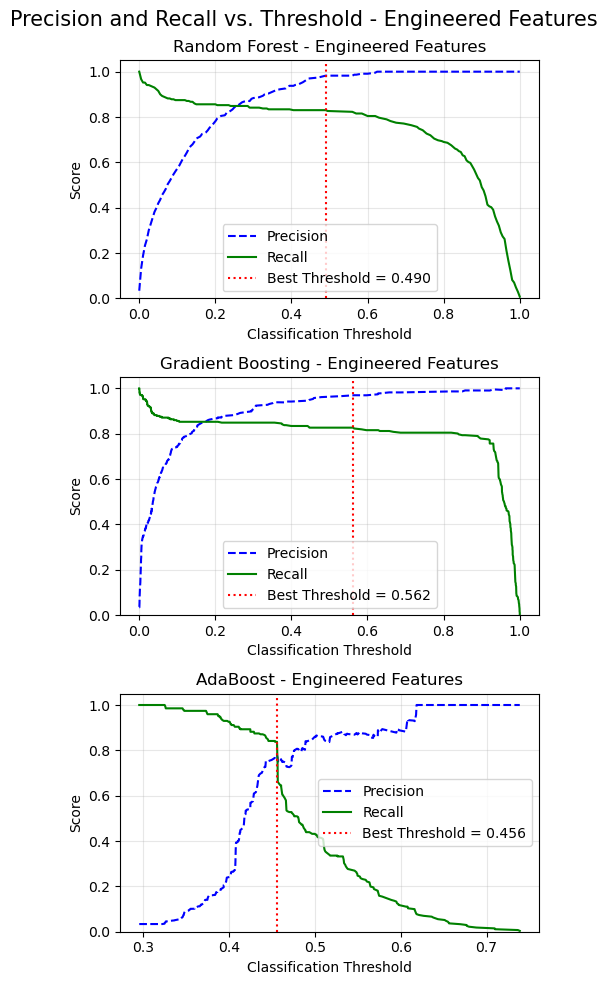

,Model,Threshold,Precision,Recall,F1
0,Random Forest_eng,0.4900,0.9825,0.8303,0.9000
1,Gradient Boosting_eng,0.3557,0.9426,0.8487,0.8932
2,AdaBoost_eng,0.4558,0.7801,0.8376,0.8078


In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_recall_curve, f1_score

y_true = y_train_eng.to_numpy().ravel()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

selected_models = [
    ("Random Forest", forest_pipe_eng),
    ("Gradient Boosting", gb_pipe_eng),
    ("AdaBoost", ada_pipe_eng)
]

fig, axes = plt.subplots(3, 1, figsize=(5, 10))

for i, (model_name, model) in enumerate(selected_models):

    y_proba_cv = cross_val_predict(
        model,
        x_train_eng,
        y_true,
        cv=cv,
        method="predict_proba"
    )[:, 1]

    precisions, recalls, thresholds = precision_recall_curve(
        y_true, y_proba_cv
    )

    f1_scores = (
        2 * precisions[:-1] * recalls[:-1]
        / (precisions[:-1] + recalls[:-1] + 1e-12)
    )

    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx]

    ax = axes[i]

    ax.plot(thresholds, precisions[:-1], "b--", label="Precision")
    ax.plot(thresholds, recalls[:-1], "g-", label="Recall")

    ax.axvline(
        best_threshold,
        color="red",
        linestyle=":",
        label=f"Best Threshold = {best_threshold:.3f}"
    )

    ax.set_title(f"{model_name} - Engineered Features")
    ax.set_xlabel("Classification Threshold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    "Precision and Recall vs. Threshold - Engineered Features",
    fontsize=15
)

plt.tight_layout()
plt.show()

selected_results = comparison[
    comparison["Model"].isin([
        "Random Forest_eng",
        "Gradient Boosting_eng",
        "AdaBoost_eng"
    ])
][[
    "Model",
    "Threshold",
    "Precision",
    "Recall",
    "F1"
]].reset_index(drop=True)

selected_results

## Final Model Selection

Based on the threshold analysis and model comparison, **Random Forest was selected as the final model**.

Although AdaBoost achieved the highest Recall (0.8376), its Precision was considerably lower (0.7801), indicating a higher number of false positive predictions.

Random Forest achieved the highest Precision (0.9825) while maintaining a competitive Recall (0.8303). It also obtained the highest F1-score (0.9000), demonstrating the best balance between Precision and Recall among the three models.

Since Random Forest provides a strong balance between detecting machine failures and minimizing false alarms, it was selected as the final model for this predictive maintenance project.

# 5. Final Model Training & Test Set Evaluation 


In this section, the final model is evaluated on the unseen test dataset using the selected classification threshold (0.49).

The model's performance is assessed using Accuracy, Precision, Recall, F1-Score, PR-AUC, and ROC-AUC.

In [24]:
from sklearn.metrics import (roc_auc_score)

final_model=forest_pipe_eng

final_model.fit(x_train_eng,y_train_eng)

y_proba_test=final_model.predict_proba(x_test_eng)[:,1]

best_threshold=0.49

y_pred_test=(y_proba_test>=best_threshold).astype(int)

test_results = {
    "Accuracy": accuracy_score(y_test, y_pred_test),
    "Precision": precision_score(y_test, y_pred_test),
    "Recall": recall_score(y_test, y_pred_test),
    "F1-Score": f1_score(y_test, y_pred_test),
    "PR-AUC": average_precision_score(y_test, y_proba_test),
    "ROC-AUC": roc_auc_score(y_test, y_proba_test)
}

pd.DataFrame(
    test_results.items(),
    columns=["Metric", "Test Score"]
).round(4)

,Metric,Test Score
0,Accuracy,0.9930
1,Precision,0.9655
2,Recall,0.8235
3,F1-Score,0.8889
4,PR-AUC,0.8876
5,ROC-AUC,0.9733


## 6. Confusion Matrix Analysis

The confusion matrix is used to analyze the model's classification performance by examining True Positives, True Negatives, False Positives, and False Negatives.

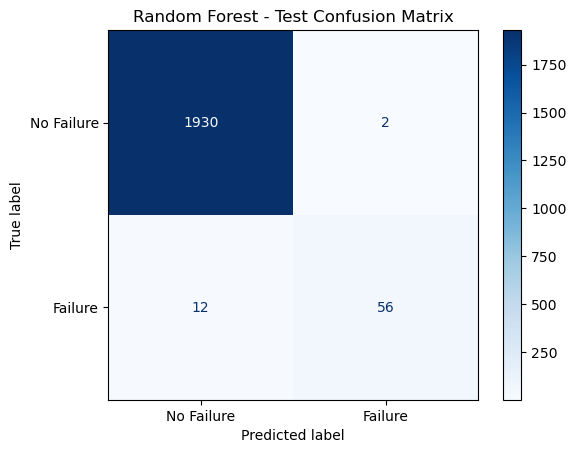

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_test)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot(cmap="Blues")
plt.title("Random Forest - Test Confusion Matrix")
plt.show()

In [26]:
import joblib
from pathlib import Path

# Project directory
project_dir = Path(
    r"C:\Users\AsuS\Downloads\ai4i-predictive-maintenance"
)

# Create models folder
model_dir = project_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Save model
joblib.dump(
    final_model,
    model_dir / "random_forest_model.joblib"
)

# Save threshold
joblib.dump(
    best_threshold,
    model_dir / "threshold.joblib"
)

# Verify saved files
print("Model saved:", (model_dir / "random_forest_model.joblib").exists())
print("Threshold saved:", (model_dir / "threshold.joblib").exists())

print("Saved in:", model_dir)

Model saved: True
Threshold saved: True
Saved in: C:\Users\AsuS\Downloads\ai4i-predictive-maintenance\models
